Banking Loan Default Prediction and Credit rick Analysis

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [94]:
bank_data = pd.read_csv('Loan_default.csv')
bank_data.head(11)

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
5,A9S62RQ7US,25,90298,90448,720,18,2,22.72,24,0.10,High School,Unemployed,Single,Yes,No,Business,Yes,1
6,H8GXPAOS71,38,111188,177025,429,80,1,19.11,12,0.16,Bachelor's,Unemployed,Single,Yes,No,Home,Yes,0
7,0HGZQKJ36W,56,126802,155511,531,67,4,8.15,60,0.43,PhD,Full-time,Married,No,No,Home,Yes,0
8,1R0N3LGNRJ,36,42053,92357,827,83,1,23.94,48,0.20,Bachelor's,Self-employed,Divorced,Yes,No,Education,No,1
9,CM9L1GTT2P,40,132784,228510,480,114,4,9.09,48,0.33,High School,Self-employed,Married,Yes,No,Other,Yes,0


In [95]:
bank_data.tail()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0
255346,ZTH91CGL0B,62,22418,18481,636,113,2,6.73,12,0.48,Bachelor's,Unemployed,Divorced,Yes,No,Education,Yes,0


In [96]:
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

In [97]:
bank_data.shape

(255347, 18)

In [98]:
bank_data.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='object')

In [99]:
bank_data.drop(['LoanID'],axis=1,inplace=True)

In [100]:
bank_data.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [101]:
bank_data.describe(include='object')

,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
count,255347,255347,255347,255347,255347,255347,255347
unique,4,4,3,2,2,5,2
top,Bachelor's,Part-time,Married,Yes,Yes,Business,Yes
freq,64366,64161,85302,127677,127742,51298,127701


In [102]:
bank_data.isnull().sum().sum()

np.int64(0)

In [103]:
bank_data["Default"].value_counts()

,count
Default,
0,225694
1,29653


In [104]:
bank_data["Default"].value_counts(normalize=True) * 100

,proportion
Default,
0,88.387175
1,11.612825


In [105]:
bank_data["EmploymentType"].unique()

array(['Full-time', 'Unemployed', 'Self-employed', 'Part-time'],
      dtype=object)

In [106]:
bank_data["LoanPurpose"].unique()

array(['Other', 'Auto', 'Business', 'Home', 'Education'], dtype=object)

In [107]:
categorical_cols = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

for col in categorical_cols:
    print("\n", col)
    print(bank_data[col].value_counts())


 Education
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

 EmploymentType
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

 MaritalStatus
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

 HasMortgage
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

 HasDependents
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

 LoanPurpose
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

 HasCoSigner
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


In [108]:
numerical_cols = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio"
]

for col in numerical_cols:
    Q1 = bank_data[col].quantile(0.25)
    Q3 = bank_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((bank_data[col] < lower) |
                (bank_data[col] > upper)).sum()

    print(col, ":", outliers)

Age : 0
Income : 0
LoanAmount : 0
CreditScore : 0
MonthsEmployed : 0
NumCreditLines : 0
InterestRate : 0
LoanTerm : 0
DTIRatio : 0


In [109]:
bank_data.dtypes.value_counts()

,count
int64,8
object,7
float64,2


In [110]:
backup_set = bank_data.copy()


Data Cleaning


In [111]:
bank_data.shape

(255347, 17)

In [112]:
bank_data.columns = bank_data.columns.str.strip() # if there would be any space it remove that

In [113]:
bank_data.duplicated().sum()

np.int64(0)

In [114]:
bank_data.isnull().sum()

,0
Age,0
Income,0
LoanAmount,0
CreditScore,0
MonthsEmployed,0
NumCreditLines,0
InterestRate,0
LoanTerm,0
DTIRatio,0
Education,0


In [115]:
bank_data[["Age","Income","LoanAmount"]].describe()

,Age,Income,LoanAmount
count,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512
std,14.990258,38963.013729,70840.706142
min,18.000000,15000.000000,5000.000000
25%,31.000000,48825.500000,66156.000000
50%,43.000000,82466.000000,127556.000000
75%,56.000000,116219.000000,188985.000000
max,69.000000,149999.000000,249999.000000


In [116]:
(bank_data["Age"] < 18).sum()

np.int64(0)

In [117]:
(bank_data["CreditScore"] < 300).sum()

np.int64(0)

In [118]:
(bank_data[['Income','LoanAmount','DTIRatio','LoanTerm','InterestRate','NumCreditLines','MonthsEmployed']]<0).sum()

,0
Income,0
LoanAmount,0
DTIRatio,0
LoanTerm,0
InterestRate,0
NumCreditLines,0
MonthsEmployed,0


EDA

<Axes: >

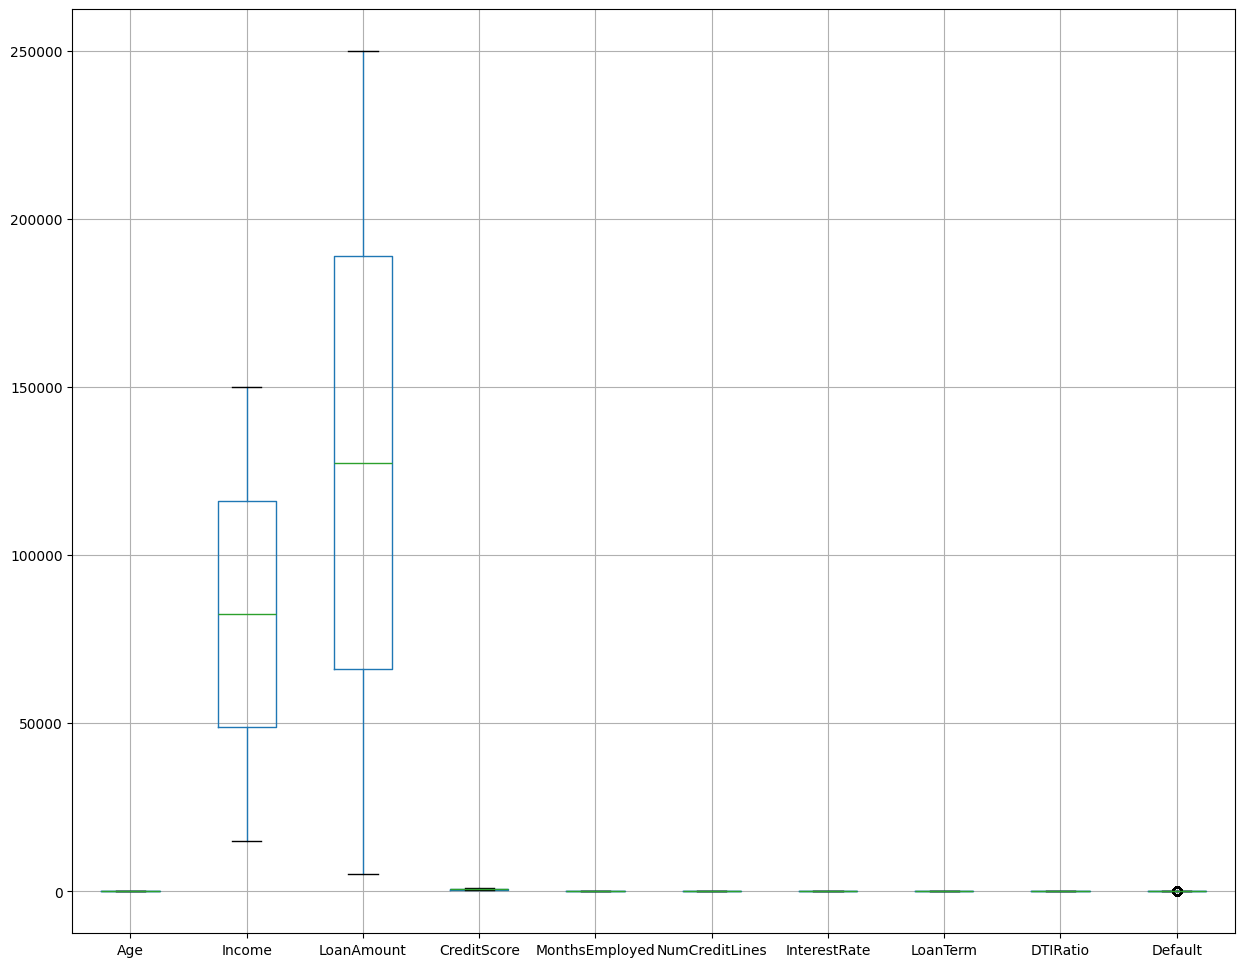

In [119]:
plt.figure(figsize=(15,12))
bank_data.boxplot()

In [120]:
bank_data["Default"].value_counts(normalize=True) * 100

,proportion
Default,
0,88.387175
1,11.612825


In [121]:
# import matplotlib.pyplot as plt

# bank_data["Default"].value_counts().sort_index().plot(kind="bar")

# plt.title("Loan Default Distribution")
# plt.xlabel("Default")
# plt.ylabel("Number of Customers")
# plt.xticks([0, 1], ["No Default", "Default"], rotation=0)

# plt.show()

as by plot we understand that the defalut numbres are not much and non- defaulter are more

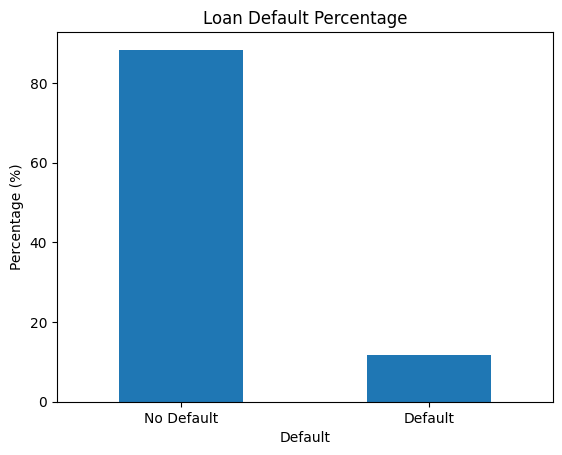

In [122]:
default_pct = bank_data["Default"].value_counts(normalize=True) * 100

default_pct.sort_index().plot(
    kind="bar"
)

plt.title("Loan Default Percentage")
plt.xlabel("Default")
plt.ylabel("Percentage (%)")
plt.xticks([0, 1], ["No Default", "Default"], rotation=0)

plt.show()

In [123]:
bank_data.groupby("Default")["CreditScore"].mean()

,CreditScore
Default,
0,576.232270
1,559.286143


In [124]:
bank_data["CreditScoreGroup"] = pd.cut(
    bank_data["CreditScore"],
    bins=[299, 500, 600, 700, 800, 900],
    labels=["300-499", "500-599", "600-699", "700-799", "800+"]
)

In [125]:
credit_default_rate = (bank_data.groupby("CreditScoreGroup",
                                         observed=True)["Default"].mean() * 100)

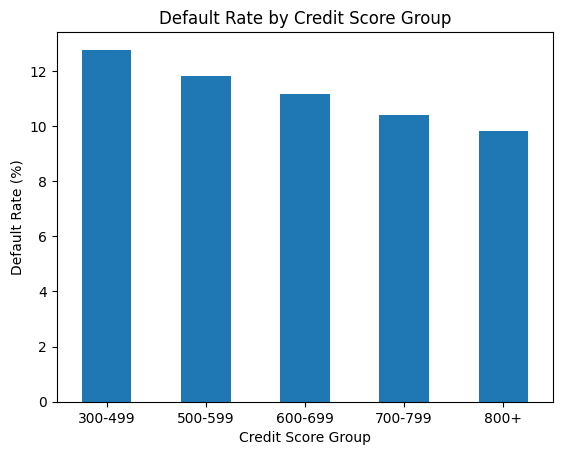

In [126]:
credit_default_rate.plot(kind="bar")

plt.title("Default Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [127]:
bank_data.groupby("Default")["Income"].mean()

,Income
Default,
0,83899.165995
1,71844.722659


In [128]:
bank_data["IncomeGroup"] = pd.cut(
    bank_data["Income"],
    bins=[0, 30000, 60000, 90000, 120000, 150000],
    labels=[
        "0-30K",
        "30K-60K",
        "60K-90K",
        "90K-120K",
        "120K-150K"
    ]
)

In [129]:
income_default_rate = (
    bank_data.groupby("IncomeGroup", observed=True)["Default"]
    .mean() * 100
)

print(income_default_rate)

IncomeGroup
0-30K        21.957402
30K-60K      12.781995
60K-90K      10.161236
90K-120K      9.301465
120K-150K     9.030242
Name: Default, dtype: float64


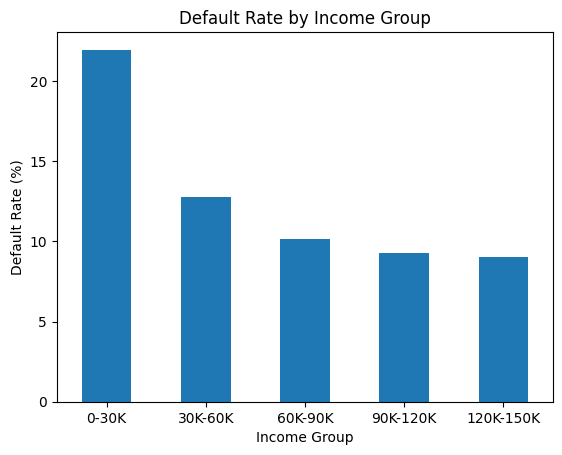

In [130]:
income_default_rate.plot(kind="bar")

plt.title("Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [131]:
bank_data.groupby("Default")["LoanAmount"].mean()

,LoanAmount
Default,
0,125353.656017
1,144515.311469


In [132]:
bank_data["LoanAmountGroup"] = pd.cut(
    bank_data["LoanAmount"],
    bins=[0, 50000, 100000, 150000, 200000, 250000],
    labels=[
        "0-50K",
        "50K-100K",
        "100K-150K",
        "150K-200K",
        "200K-250K"
    ]
)

In [133]:
loan_default_rate = (
    bank_data.groupby("LoanAmountGroup", observed=True)["Default"]
    .mean() * 100
)

print(loan_default_rate)

LoanAmountGroup
0-50K         8.063112
50K-100K      9.438790
100K-150K    11.160585
150K-200K    13.245224
200K-250K    15.786261
Name: Default, dtype: float64


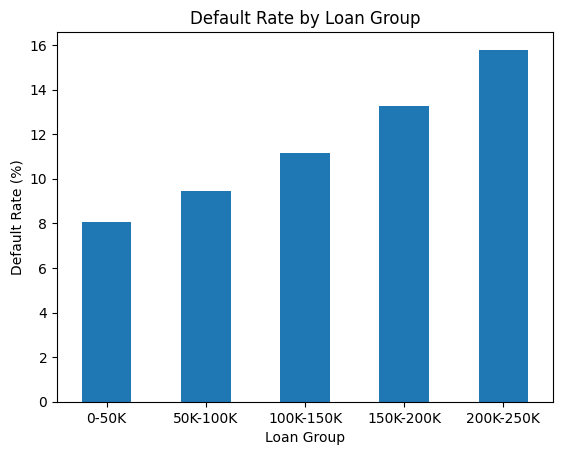

In [134]:
loan_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Group")
plt.xlabel("Loan Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [135]:
bank_data.groupby("Default")["InterestRate"].mean()

,InterestRate
Default,
0,13.176994
1,15.896227


In [136]:
bank_data["InterestRateGroup"] = pd.cut(
    bank_data["InterestRate"],
    bins=[0, 5, 10, 15, 20, 25],
    labels=[
        "0-5%",
        "5-10%",
        "10-15%",
        "15-20%",
        "20-25%"
    ]
)

In [137]:
interest_default_rate = (
    bank_data.groupby("InterestRateGroup", observed=True)["Default"]
    .mean() * 100
)

print(interest_default_rate)

InterestRateGroup
0-5%       6.022468
5-10%      7.686089
10-15%    10.546358
15-20%    13.794609
20-25%    17.819552
Name: Default, dtype: float64


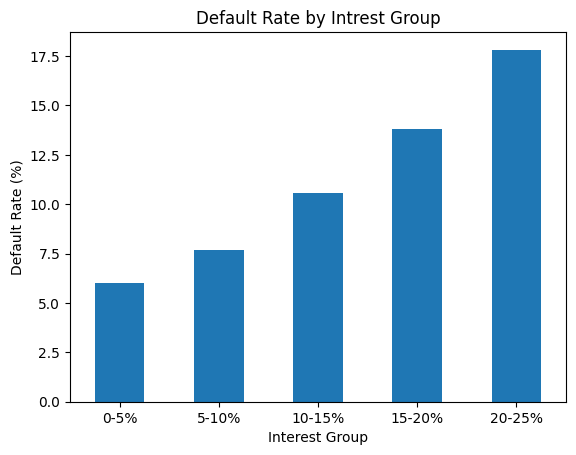

In [138]:
interest_default_rate.plot(kind="bar")

plt.title("Default Rate by Intrest Group")
plt.xlabel("Interest Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [139]:
bank_data.groupby("Default")["DTIRatio"].mean()

,DTIRatio
Default,
0,0.498602
1,0.512467


In [140]:
bank_data["DTIGroup"] = pd.cut(
    bank_data["DTIRatio"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=[
        "0-20%",
        "20-40%",
        "40-60%",
        "60-80%",
        "80-100%"
    ],
    include_lowest=True
)

In [141]:
dti_default_rate = (
    bank_data.groupby("DTIGroup", observed=True)["Default"]
    .mean() * 100
)

print(dti_default_rate)

DTIGroup
0-20%      10.363143
20-40%     11.164182
40-60%     11.823581
60-80%     12.238391
80-100%    12.175918
Name: Default, dtype: float64


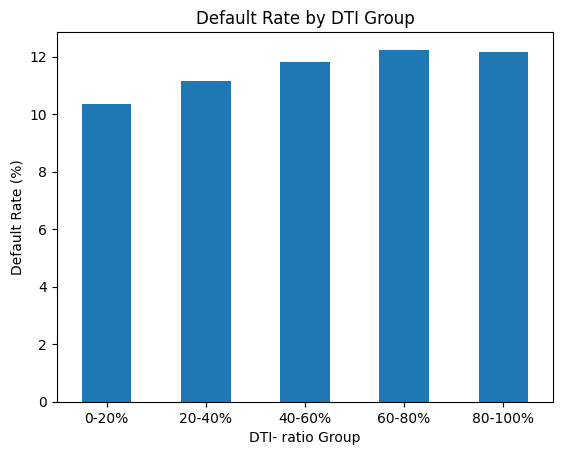

In [142]:
dti_default_rate.plot(kind="bar")

plt.title("Default Rate by DTI Group")
plt.xlabel("DTI- ratio Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [143]:
bank_data["LoanTerm"].value_counts().sort_index()

,count
LoanTerm,
12,50957
24,51009
36,51061
48,51166
60,51154


In [144]:
loan_term_default_rate = (
    bank_data.groupby("LoanTerm")["Default"]
    .mean() * 100
)

print(loan_term_default_rate)

LoanTerm
12    11.617638
24    11.607755
36    11.568516
48    11.574092
60    11.696055
Name: Default, dtype: float64


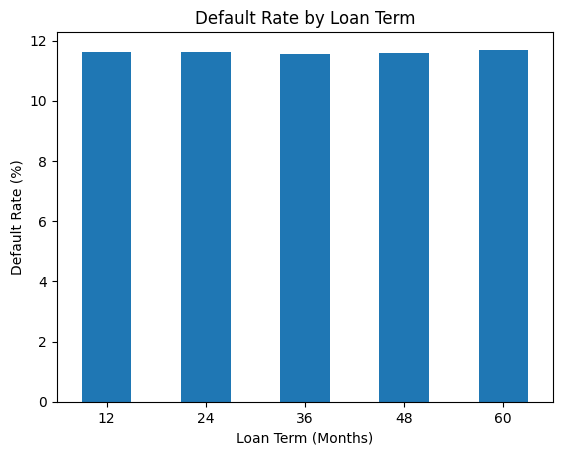

In [145]:
loan_term_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Term")
plt.xlabel("Loan Term (Months)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [146]:
bank_data["NumCreditLines"].value_counts().sort_index()

,count
NumCreditLines,
1,63554
2,64130
3,63834
4,63829


In [147]:
credit_lines_default_rate = (
    bank_data.groupby("NumCreditLines")["Default"]
    .mean() * 100
)

print(credit_lines_default_rate)

NumCreditLines
1    10.523334
2    11.058787
3    11.924680
4    12.942393
Name: Default, dtype: float64


categorical terms

In [148]:
employment_default_rate = (
    bank_data.groupby("EmploymentType")["Default"]
    .mean() * 100
)

print(employment_default_rate)

EmploymentType
Full-time         9.463366
Part-time        11.965213
Self-employed    11.462029
Unemployed       13.552895
Name: Default, dtype: float64


In [149]:
education_default_rate = (
    bank_data.groupby("Education")["Default"]
    .mean() * 100
)

print(education_default_rate)

Education
Bachelor's     12.101109
High School    12.878895
Master's       10.871721
PhD            10.585958
Name: Default, dtype: float64


In [150]:
marital_default_rate = (
    bank_data.groupby("MaritalStatus")["Default"]
    .mean() * 100
)

print(marital_default_rate)

MaritalStatus
Divorced    12.532781
Married     10.397177
Single      11.912436
Name: Default, dtype: float64


In [151]:
mortgage_default_rate = (
    bank_data.groupby("HasMortgage")["Default"]
    .mean() * 100
)

print(mortgage_default_rate)

HasMortgage
No     12.345108
Yes    10.880581
Name: Default, dtype: float64


In [152]:
dependents_default_rate = (
    bank_data.groupby("HasDependents")["Default"]
    .mean() * 100
)

print(dependents_default_rate)

HasDependents
No     12.724423
Yes    10.502419
Name: Default, dtype: float64


In [153]:
loan_purpose_default_rate = (
    bank_data.groupby("LoanPurpose")["Default"]
    .mean() * 100
)

print(loan_purpose_default_rate)

LoanPurpose
Auto         11.881441
Business     12.326017
Education    11.838055
Home         10.234762
Other        11.788506
Name: Default, dtype: float64


In [154]:
cosigner_default_rate = (
    bank_data.groupby("HasCoSigner")["Default"]
    .mean() * 100
)

print(cosigner_default_rate)

HasCoSigner
No     12.866051
Yes    10.360138
Name: Default, dtype: float64


Borrowers without a co-signer have a higher observed default rate (12.87%) than borrowers with a co-signer (10.36%). This suggests that co-signer status is associated with default risk in the dataset.

In [155]:
correlation_matrix = bank_data.select_dtypes(include="number").corr()

correlation_matrix

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000000,-0.001244,-0.002213,-0.000548,-0.000341,-0.000890,-0.001127,0.000263,-0.004689,-0.167783
Income,-0.001244,1.000000,-0.000865,-0.001430,0.002675,-0.002016,-0.002303,-0.000998,0.000205,-0.099119
LoanAmount,-0.002213,-0.000865,1.000000,0.001261,0.002817,0.000794,-0.002291,0.002538,0.001122,0.086659
CreditScore,-0.000548,-0.001430,0.001261,1.000000,0.000613,0.000016,0.000436,0.001130,-0.001039,-0.034166
MonthsEmployed,-0.000341,0.002675,0.002817,0.000613,1.000000,0.001267,0.000096,-0.001166,0.001765,-0.097374
NumCreditLines,-0.000890,-0.002016,0.000794,0.000016,0.001267,1.000000,-0.000297,-0.000226,-0.000586,0.028330
InterestRate,-0.001127,-0.002303,-0.002291,0.000436,0.000096,-0.000297,1.000000,0.000892,0.000575,0.131273
LoanTerm,0.000263,-0.000998,0.002538,0.001130,-0.001166,-0.000226,0.000892,1.000000,0.002273,0.000545
DTIRatio,-0.004689,0.000205,0.001122,-0.001039,0.001765,-0.000586,0.000575,0.002273,1.000000,0.019236
Default,-0.167783,-0.099119,0.086659,-0.034166,-0.097374,0.028330,0.131273,0.000545,0.019236,1.000000


In [156]:
correlation_matrix["Default"].sort_values(ascending=False)

,Default
Default,1.000000
InterestRate,0.131273
LoanAmount,0.086659
NumCreditLines,0.028330
DTIRatio,0.019236
LoanTerm,0.000545
CreditScore,-0.034166
MonthsEmployed,-0.097374
Income,-0.099119
Age,-0.167783


In [157]:
bank_data["AgeGroup"] = pd.cut(
    bank_data["Age"],
    bins=[17, 25, 35, 45, 55, 65, 70],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66-69"
    ]
)

In [158]:
age_default_rate = (
    bank_data.groupby("AgeGroup", observed=True)["Default"]
    .mean() * 100
)

print(age_default_rate)

AgeGroup
18-25    20.760714
26-35    16.078368
36-45    11.548151
46-55     8.449988
56-65     5.859813
66-69     4.601888
Name: Default, dtype: float64


In [159]:
bank_data["EmploymentDurationGroup"] = pd.cut(
    bank_data["MonthsEmployed"],
    bins=[-1, 24, 48, 72, 96, 120],
    labels=[
        "0-24 months",
        "25-48 months",
        "49-72 months",
        "73-96 months",
        "97-120 months"
    ]
)

In [160]:
employment_duration_default_rate = (
    bank_data.groupby(
        "EmploymentDurationGroup",
        observed=True
    )["Default"]
    .mean() * 100
)

print(employment_duration_default_rate)

EmploymentDurationGroup
0-24 months      16.236671
25-48 months     13.521281
49-72 months     11.058879
73-96 months      9.301780
97-120 months     7.611822
Name: Default, dtype: float64


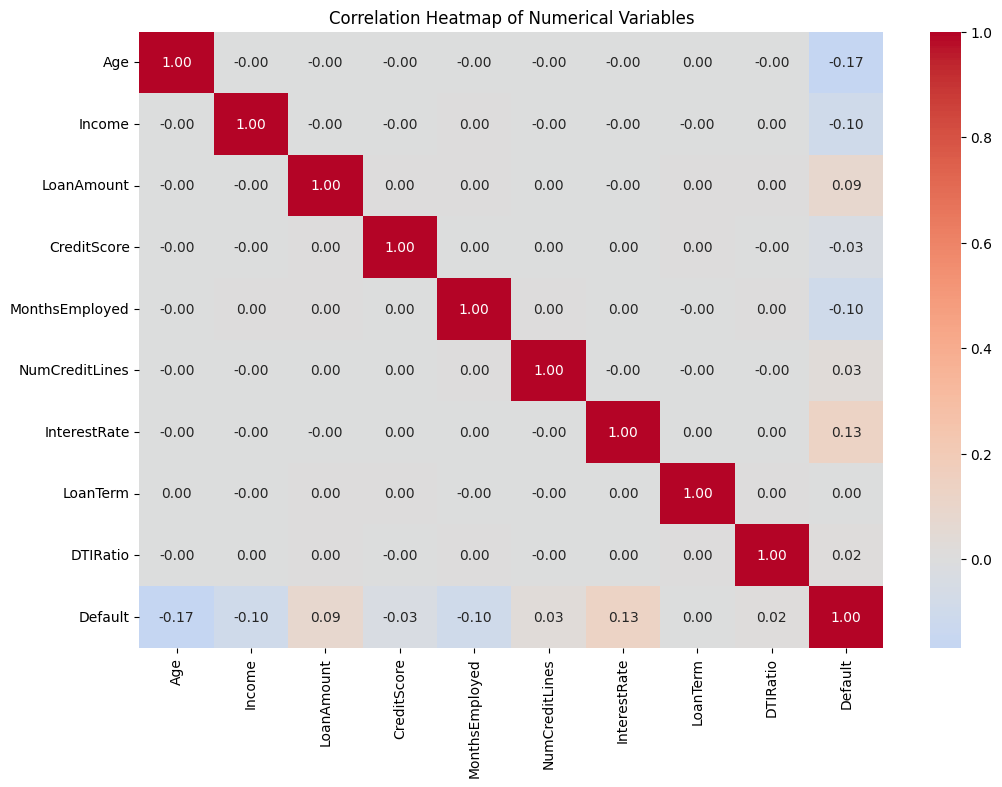

In [161]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

feature engineering

In [162]:
bank_data.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education',
       'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents',
       'LoanPurpose', 'HasCoSigner', 'Default', 'CreditScoreGroup',
       'IncomeGroup', 'LoanAmountGroup', 'InterestRateGroup', 'DTIGroup',
       'AgeGroup', 'EmploymentDurationGroup'],
      dtype='object')

In [163]:
bank_data["LoanToIncome"] = (
    bank_data["LoanAmount"] / bank_data["Income"]
)

In [164]:
bank_data["LoanToIncome"]

,LoanToIncome
0,0.588262
1,2.467481
2,1.534154
3,1.412638
4,0.447179
...,...
255342,5.547329
255343,3.655208
255344,2.455718
255345,0.711734


In [165]:
monthly_rate = bank_data["InterestRate"] / (12 * 100)

bank_data["EstimatedMonthlyPayment"] = (
    bank_data["LoanAmount"] * monthly_rate *
    (1 + monthly_rate) ** bank_data["LoanTerm"]
) / (
    (1 + monthly_rate) ** bank_data["LoanTerm"] - 1
)

In [166]:
bank_data[
    ["LoanAmount", "InterestRate", "LoanTerm",
     "EstimatedMonthlyPayment"]
].head()

,LoanAmount,InterestRate,LoanTerm,EstimatedMonthlyPayment
0,50587,15.23,36,1759.318045
1,124440,4.81,60,2337.519546
2,129188,21.17,24,6649.201648
3,44799,7.07,24,2007.188719
4,9139,6.51,48,216.773108


splitting

In [167]:
x = bank_data.drop("Default", axis=1)
y = bank_data["Default"]

In [168]:
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (255347, 25)
y shape: (255347,)


In [169]:
eda_columns = [
    "IncomeGroup",
    "LoanAmountGroup",
    "InterestRateGroup",
    "DTIGroup",
    "AgeGroup",
    "EmploymentDurationGroup",
    "LoanIncomeGroup"
]

x = x.drop(columns=eda_columns, errors="ignore")

In [170]:
x.shape

(255347, 19)

In [171]:
y.isnull().sum()

np.int64(0)

In [172]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [173]:
print("X_train:", x_train.shape)
print("X_test :", x_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (204277, 19)
X_test : (51070, 19)
y_train: (204277,)
y_test : (51070,)


# need clarity ....

In [174]:
categorical_cols = x_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = x_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'CreditScoreGroup']
Numerical columns: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'LoanToIncome', 'EstimatedMonthlyPayment']


In [175]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_cols
        )
    ]
)

In [176]:
print(type(x_train))

<class 'pandas.core.frame.DataFrame'>


In [177]:
# from sklearn.linear_model import LogisticRegression

# logistic_model = LogisticRegression(max_iter=1000,random_state=42)

# logistic_model.fit(x_train_processed, y_train)

In [178]:
# y_pred = logistic_model.predict(x_test_processed)

In [179]:
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# print("Accuracy :", accuracy_score(y_test, y_pred))
# print("Precision:", precision_score(y_test, y_pred))
# print("Recall   :", recall_score(y_test, y_pred))
# print("F1 Score :", f1_score(y_test, y_pred))

piprline of model training

In [180]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor),("model", logistic_model)
    ]
)

In [181]:
logistic_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'LoanPurpose', 'HasCoSigner',
                                                   'CreditScoreGroup']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio', 'LoanToIncome',
                                                   'EstimatedMonthlyPayment'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [182]:
y_pred = logistic_pipeline.predict(x_test)

In [183]:
y_prob = logistic_pipeline.predict_proba(x_test)[:, 1]

In [184]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[44882   257]
 [ 5521   410]]


In [185]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8868611709418446


In [186]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.6146926536731634


In [187]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.06912830888551677


In [188]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)

F1 Score: 0.1242800848742043


In [189]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.99      0.94     45139
           1       0.61      0.07      0.12      5931

    accuracy                           0.89     51070
   macro avg       0.75      0.53      0.53     51070
weighted avg       0.86      0.89      0.84     51070



In [190]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.7615757511253134


Class_weight ='blanced'

In [191]:
bank_data["Default"].value_counts()

,count
Default,
0,225694
1,29653


In [192]:
class_weight="balanced"

In [193]:
logistic_model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

In [194]:
logistic_pipeline_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model_balanced)
    ]
)

In [195]:
logistic_pipeline_balanced.fit(
    x_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'LoanPurpose', 'HasCoSigner',
                                                   'CreditScoreGroup']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio', 'LoanToIncome',
                                                   'EstimatedMonthlyPayment'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [196]:
y_pred_balanced = logistic_pipeline_balanced.predict(x_test)

In [197]:
y_prob_balanced = (
    logistic_pipeline_balanced.predict_proba(x_test)[:, 1]
)

In [198]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_balanced = accuracy_score(
    y_test,
    y_pred_balanced
)

precision_balanced = precision_score(
    y_test,
    y_pred_balanced
)

recall_balanced = recall_score(
    y_test,
    y_pred_balanced
)

f1_balanced = f1_score(
    y_test,
    y_pred_balanced
)

auc_balanced = roc_auc_score(
    y_test,
    y_prob_balanced
)

In [199]:
print("Accuracy:", accuracy_balanced)
print("Precision:", precision_balanced)
print("Recall:", recall_balanced)
print("F1 Score:", f1_balanced)
print("ROC-AUC:", auc_balanced)

Accuracy: 0.6907577834345017
Precision: 0.22828961869076483
Recall: 0.6985331310065757
F1 Score: 0.34411728061796587
ROC-AUC: 0.7614791948087709


In [200]:
from sklearn.metrics import confusion_matrix

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced
)

print(cm_balanced)

[[31134 14005]
 [ 1788  4143]]


In [201]:
print(
    classification_report(
        y_test,
        y_pred_balanced
    )
)

              precision    recall  f1-score   support

           0       0.95      0.69      0.80     45139
           1       0.23      0.70      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.75     51070



thersold

In [202]:
from sklearn.metrics import precision_recall_curve

y_prob = logistic_pipeline.predict_proba(x_test)[:, 1]

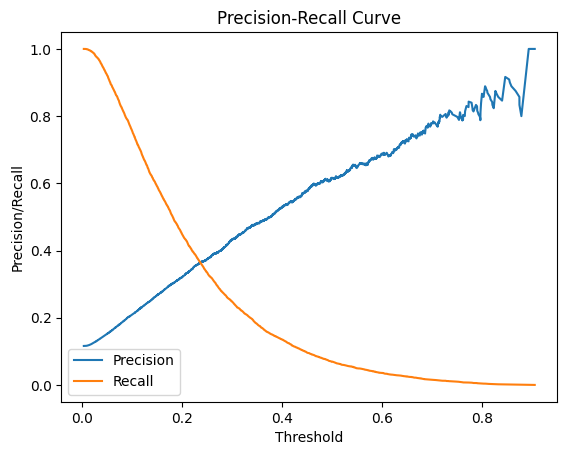

In [203]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Precision/Recall')
plt.legend()
plt.title('Precision-Recall Curve')
plt.show()

In [204]:
y_pred_thresh_30 = (y_prob_balanced >= 0.3).astype(int)
print('New Classification Report(Threshold 0.3):')
print(classification_report(y_test, y_pred_thresh_30))

New Classification Report(Threshold 0.3):
              precision    recall  f1-score   support

           0       0.97      0.35      0.52     45139
           1       0.16      0.91      0.27      5931

    accuracy                           0.42     51070
   macro avg       0.56      0.63      0.39     51070
weighted avg       0.87      0.42      0.49     51070



In [205]:
y_pred_thresh_25 = (y_prob_balanced >= 0.25).astype(int)
print('New Classification Report(Threshold 0.25):')
print(classification_report(y_test, y_pred_thresh_25))

New Classification Report(Threshold 0.25):
              precision    recall  f1-score   support

           0       0.97      0.26      0.41     45139
           1       0.14      0.94      0.25      5931

    accuracy                           0.34     51070
   macro avg       0.56      0.60      0.33     51070
weighted avg       0.88      0.34      0.39     51070



In [206]:
roc_auc_score(y_test, y_prob_balanced)

np.float64(0.7614791948087709)

In [207]:
final_cm = confusion_matrix(
    y_test,
    y_pred_thresh_25
)

print(final_cm)

[[11727 33412]
 [  327  5604]]


In [208]:
model = logistic_pipeline_balanced.named_steps["model"]

In [209]:
feature_names = (
    logistic_pipeline_balanced
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

In [210]:
print(feature_names)

["categorical__Education_Bachelor's" 'categorical__Education_High School'
 "categorical__Education_Master's" 'categorical__Education_PhD'
 'categorical__EmploymentType_Full-time'
 'categorical__EmploymentType_Part-time'
 'categorical__EmploymentType_Self-employed'
 'categorical__EmploymentType_Unemployed'
 'categorical__MaritalStatus_Divorced'
 'categorical__MaritalStatus_Married' 'categorical__MaritalStatus_Single'
 'categorical__HasMortgage_No' 'categorical__HasMortgage_Yes'
 'categorical__HasDependents_No' 'categorical__HasDependents_Yes'
 'categorical__LoanPurpose_Auto' 'categorical__LoanPurpose_Business'
 'categorical__LoanPurpose_Education' 'categorical__LoanPurpose_Home'
 'categorical__LoanPurpose_Other' 'categorical__HasCoSigner_No'
 'categorical__HasCoSigner_Yes' 'categorical__CreditScoreGroup_300-499'
 'categorical__CreditScoreGroup_500-599'
 'categorical__CreditScoreGroup_600-699'
 'categorical__CreditScoreGroup_700-799'
 'categorical__CreditScoreGroup_800+' 'numerical__Age'

In [211]:
coefficients = model.coef_[0]

In [212]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

In [213]:
coef_df.head()

,Feature,Coefficient
0,categorical__Education_Bachelor's,0.036273
1,categorical__Education_High School,0.114528
2,categorical__Education_Master's,-0.103061
3,categorical__Education_PhD,-0.145057
4,categorical__EmploymentType_Full-time,-0.264974


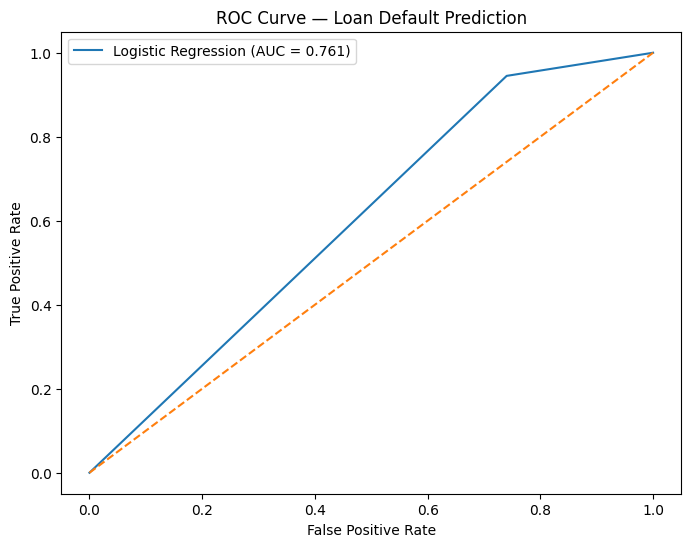

In [214]:
from sklearn.metrics import roc_curve , roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_thresh_25
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_balanced:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Loan Default Prediction")
plt.legend()
plt.show()

In [215]:
bank_data.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education',
       'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents',
       'LoanPurpose', 'HasCoSigner', 'Default', 'CreditScoreGroup',
       'IncomeGroup', 'LoanAmountGroup', 'InterestRateGroup', 'DTIGroup',
       'AgeGroup', 'EmploymentDurationGroup', 'LoanToIncome',
       'EstimatedMonthlyPayment'],
      dtype='object')